In [1]:
import os
import shutil
import random
import yaml
from glob import glob
from collections import defaultdict

import pandas as pd
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm

random.seed(42)

DBA_DIR = "/kaggle/input/datasets/quynnguynthanh/dba-yolo-clean"
DFIRE_DIR    = "/kaggle/input/datasets/quynnguynthanh/d-fire-yolo"
BOWFIRE_DIR  = "/kaggle/input/datasets/malligasenthil/bowfire"
FLAME_TRAIN  = "/kaggle/input/datasets/smrutisanchitadas/flame-dataset-fire-classification/Training/Training/No_Fire"
FLAME_TEST   = "/kaggle/input/datasets/smrutisanchitadas/flame-dataset-fire-classification/Test/Test/No_Fire"
FLAME_FIRE_TRAIN = FLAME_TRAIN.replace("No_Fire", "Fire")
FLAME_FIRE_TEST  = FLAME_TEST.replace("No_Fire", "Fire")
FINAL_DIR = "/kaggle/working/FinalSFD_YOLO_Dataset"

DBA_IMG_DIR = os.path.join(DBA_DIR, 'JPEGImages')
DBA_LBL_DIR = os.path.join(DBA_DIR, 'txt')

# Tỉ lệ background
TOTAL_BG_RATIO   = 0.20   # tổng background
BG_RATIO_DFIRE   = 0.10
BG_RATIO_OTHERS  = 0.10

VAL_RATIO_FROM_TRAIN = 0.15  # tách 15% train gốc của D-Fire thành val

# Chia train/val/test cho DBA-Fire
DBA_TRAIN_RATIO = 0.68
DBA_VAL_RATIO   = 0.12
DBA_TEST_RATIO  = 0.20

### Thông tin D-Fire

In [2]:
def classify_label_file(txt_path):
    """Quy ước D-Fire: 0 = smoke, 1 = fire."""
    if not os.path.exists(txt_path):
        return 'background'
    with open(txt_path, 'r') as f:
        lines = [l.strip() for l in f if l.strip()]
    if not lines:
        return 'background'
    ids = set(int(l.split()[0]) for l in lines)
    if ids == {0, 1}:
        return 'both'
    elif ids == {0}:
        return 'smoke_only'
    elif ids == {1}:
        return 'fire_only'
    return 'background'

def collect_dfire_by_category(images_dir, labels_dir):
    """Trả về dict: category -> list ảnh thuộc category đó."""
    cats = defaultdict(list)
    for img_path in glob(os.path.join(images_dir, '*.[jp][pn]*')):
        txt_path = os.path.join(labels_dir, os.path.splitext(os.path.basename(img_path))[0] + '.txt')
        cats[classify_label_file(txt_path)].append(img_path)
    return cats

dfire_train_raw = collect_dfire_by_category(f"{DFIRE_DIR}/train/images", f"{DFIRE_DIR}/train/labels")
dfire_test_raw  = collect_dfire_by_category(f"{DFIRE_DIR}/test/images",  f"{DFIRE_DIR}/test/labels")

def print_cat_summary(name, cats):
    total = sum(len(v) for v in cats.values())
    print(f"{name} (Tổng: {total} ảnh)")
    for c in ['fire_only', 'smoke_only', 'both', 'background']:
        print(f"   {c:12s}: {len(cats.get(c, []))} ảnh")
    print()

print("D-FIRE")
print_cat_summary("TRAIN (gốc, chưa tách val)", dfire_train_raw)
print_cat_summary("TEST", dfire_test_raw)

D-FIRE
TRAIN (gốc, chưa tách val) (Tổng: 17221 ảnh)
   fire_only   : 944 ảnh
   smoke_only  : 4681 ảnh
   both        : 3763 ảnh
   background  : 7833 ảnh

TEST (Tổng: 4306 ảnh)
   fire_only   : 220 ảnh
   smoke_only  : 1186 ảnh
   both        : 895 ảnh
   background  : 2005 ảnh



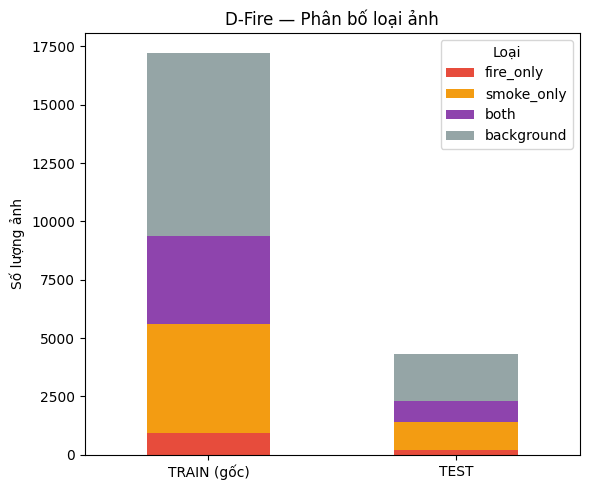

In [3]:
df_dfire_new = pd.DataFrame({
    'TRAIN (gốc)': {c: len(dfire_train_raw.get(c, [])) for c in ['fire_only', 'smoke_only', 'both', 'background']},
    'TEST':        {c: len(dfire_test_raw.get(c, []))  for c in ['fire_only', 'smoke_only', 'both', 'background']},
}).T

df_dfire_new.plot(kind='bar', stacked=True, figsize=(6, 5), color=['#e74c3c', '#f39c12', '#8e44ad', '#95a5a6'])
plt.title('D-Fire — Phân bố loại ảnh')
plt.ylabel('Số lượng ảnh')
plt.xticks(rotation=0)
plt.legend(title='Loại')
plt.tight_layout()
plt.show()

### Thông tin BoWFire

BoWFire
Tổng ảnh: 226
  - Ảnh fire  (hiện KHÔNG dùng trong pipeline): 119
  - Ảnh not_fire (dùng làm background)        : 107


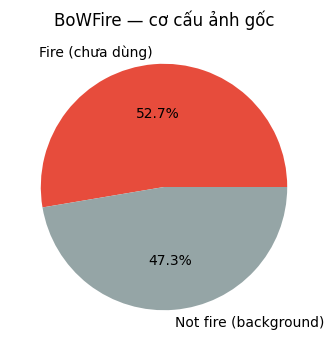

In [4]:
bowfire_all = glob(os.path.join(BOWFIRE_DIR, '*.[jp][pn]*'))
bowfire_not_fire = [f for f in bowfire_all if 'not_fire' in os.path.basename(f)]
bowfire_fire = [f for f in bowfire_all if 'not_fire' not in os.path.basename(f) and 'fire' in os.path.basename(f)]

print("BoWFire")
print(f"Tổng ảnh: {len(bowfire_all)}")
print(f"  - Ảnh fire  (hiện KHÔNG dùng trong pipeline): {len(bowfire_fire)}")
print(f"  - Ảnh not_fire (dùng làm background)        : {len(bowfire_not_fire)}")

plt.figure(figsize=(4, 4))
plt.pie([len(bowfire_fire), len(bowfire_not_fire)],
        labels=['Fire (chưa dùng)', 'Not fire (background)'],
        autopct='%1.1f%%', colors=['#e74c3c', '#95a5a6'])
plt.title('BoWFire — cơ cấu ảnh gốc')
plt.show()

### Thông tin FLAME

FLAME
Train - Fire      : 25018
Train - No_Fire   : 14357
Test - Fire       : 5137
Test - No_Fire    : 3480


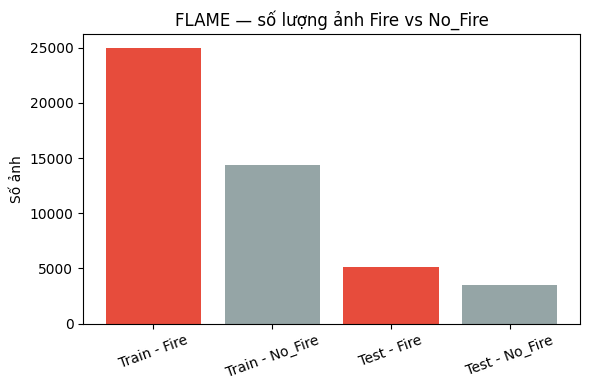

In [5]:
flame_trainval_pool = glob(os.path.join(FLAME_TRAIN, '*.[jp][pn]*')) if os.path.exists(FLAME_TRAIN) else []
flame_test_pool = glob(os.path.join(FLAME_TEST, '*.[jp][pn]*')) if os.path.exists(FLAME_TEST) else []

flame_counts = {
    'Train - Fire':    len(glob(os.path.join(FLAME_FIRE_TRAIN, '*.[jp][pn]*'))) if os.path.exists(FLAME_FIRE_TRAIN) else 0,
    'Train - No_Fire': len(flame_trainval_pool),
    'Test - Fire':     len(glob(os.path.join(FLAME_FIRE_TEST, '*.[jp][pn]*'))) if os.path.exists(FLAME_FIRE_TEST) else 0,
    'Test - No_Fire':  len(flame_test_pool),
}

print("FLAME")
for k, v in flame_counts.items():
    print(f"{k:18s}: {v}")

plt.figure(figsize=(6, 4))
plt.bar(flame_counts.keys(), flame_counts.values(), color=['#e74c3c', '#95a5a6', '#e74c3c', '#95a5a6'])
plt.title('FLAME — số lượng ảnh Fire vs No_Fire')
plt.ylabel('Số ảnh')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### Thông tin DBA-Fire

DBA-FIRE (nguồn gốc, chưa chia train/val/test)
TOÀN BỘ (Tổng: 3905 ảnh)
   fire_only   : 2134 ảnh
   smoke_only  : 699 ảnh
   both        : 1072 ảnh
   background  : 0 ảnh



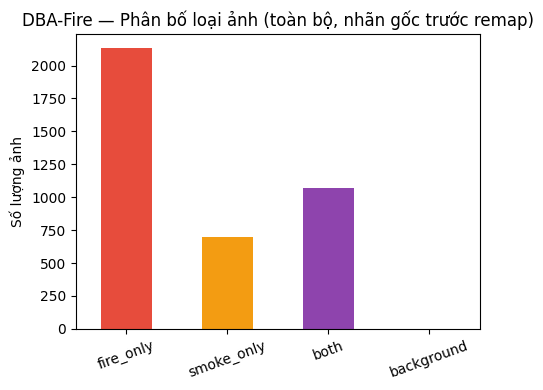

In [6]:
def classify_dba_label(txt_path, fire_id=0, smoke_id=1):
    """Quy ước DBA-Fire: 0 = fire, 1 = smoke - NGƯỢC với D-Fire (0=smoke,1=fire).
    Sẽ remap lại khi copy vào FINAL_DIR ở Cell gộp chính."""
    with open(txt_path) as f:
        lines = [l.strip() for l in f if l.strip()]
    if not lines:
        return 'background'
    ids = set(int(l.split()[0]) for l in lines)
    if fire_id in ids and smoke_id in ids:
        return 'both'
    elif fire_id in ids:
        return 'fire_only'
    elif smoke_id in ids:
        return 'smoke_only'
    return 'background'

dba_img_files = sorted([f for f in os.listdir(DBA_IMG_DIR) if f.lower().endswith(('.jpg', '.jpeg', '.png'))])

dba_cats_raw = defaultdict(list)
for fname in dba_img_files:
    base = os.path.splitext(fname)[0]
    txt_path = os.path.join(DBA_LBL_DIR, base + '.txt')
    dba_cats_raw[classify_dba_label(txt_path)].append(fname)

print("DBA-FIRE (nguồn gốc, chưa chia train/val/test)")
print_cat_summary("TOÀN BỘ", dba_cats_raw)

df_dba = pd.Series({c: len(dba_cats_raw.get(c, [])) for c in ['fire_only', 'smoke_only', 'both', 'background']})
df_dba.plot(kind='bar', figsize=(5, 4), color=['#e74c3c', '#f39c12', '#8e44ad', '#95a5a6'])
plt.title('DBA-Fire — Phân bố loại ảnh (toàn bộ, nhãn gốc trước remap)')
plt.ylabel('Số lượng ảnh')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### Tách Val từ Train (stratified theo từng loại ảnh)

In [7]:
def stratified_split(cats_dict, val_ratio):
    train_out, val_out = defaultdict(list), defaultdict(list)
    for cat, files in cats_dict.items():
        files = files.copy()
        random.shuffle(files)
        n_val = int(len(files) * val_ratio)
        val_out[cat] = files[:n_val]
        train_out[cat] = files[n_val:]
    return train_out, val_out

dfire_train_split, dfire_val_split = stratified_split(dfire_train_raw, VAL_RATIO_FROM_TRAIN)
dfire_test_split = dfire_test_raw

for name, cats in [('TRAIN (sau tách)', dfire_train_split), ('VAL (mới tách)', dfire_val_split), ('TEST', dfire_test_split)]:
    print_cat_summary(name, cats)

TRAIN (sau tách) (Tổng: 14640 ảnh)
   fire_only   : 803 ảnh
   smoke_only  : 3979 ảnh
   both        : 3199 ảnh
   background  : 6659 ảnh

VAL (mới tách) (Tổng: 2581 ảnh)
   fire_only   : 141 ảnh
   smoke_only  : 702 ảnh
   both        : 564 ảnh
   background  : 1174 ảnh

TEST (Tổng: 4306 ảnh)
   fire_only   : 220 ảnh
   smoke_only  : 1186 ảnh
   both        : 895 ảnh
   background  : 2005 ảnh



In [8]:
def three_way_split(cats_dict, train_ratio, val_ratio, test_ratio):
    """Chia 1 pool thành 3 tập, stratified theo từng category — dùng cho DBA-Fire vì nó chưa có sẵn split."""
    assert abs(train_ratio + val_ratio + test_ratio - 1.0) < 1e-6
    train_out, val_out, test_out = defaultdict(list), defaultdict(list), defaultdict(list)
    for cat, files in cats_dict.items():
        files = files.copy()
        random.shuffle(files)
        n = len(files)
        n_train = int(n * train_ratio)
        n_val = int(n * val_ratio)
        train_out[cat] = files[:n_train]
        val_out[cat] = files[n_train:n_train + n_val]
        test_out[cat] = files[n_train + n_val:]
    return train_out, val_out, test_out

dba_train_split, dba_val_split, dba_test_split = three_way_split(
    dba_cats_raw, DBA_TRAIN_RATIO, DBA_VAL_RATIO, DBA_TEST_RATIO
)

for name, cats in [('DBA-Train', dba_train_split), ('DBA-Val', dba_val_split), ('DBA-Test', dba_test_split)]:
    print_cat_summary(name, cats)

DBA-Train (Tổng: 2654 ảnh)
   fire_only   : 1451 ảnh
   smoke_only  : 475 ảnh
   both        : 728 ảnh
   background  : 0 ảnh

DBA-Val (Tổng: 467 ảnh)
   fire_only   : 256 ảnh
   smoke_only  : 83 ảnh
   both        : 128 ảnh
   background  : 0 ảnh

DBA-Test (Tổng: 784 ảnh)
   fire_only   : 427 ảnh
   smoke_only  : 141 ảnh
   both        : 216 ảnh
   background  : 0 ảnh



### So sánh quy mô 3 dataset(trước khi gộp)

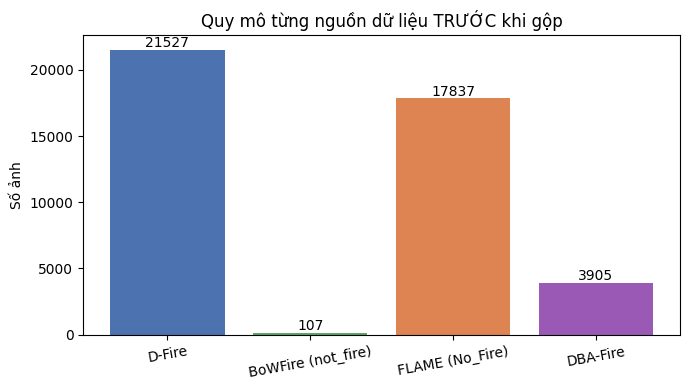

In [9]:
n_dfire_total = sum(len(v) for v in dfire_train_raw.values()) + sum(len(v) for v in dfire_test_raw.values())
n_dba_total = sum(len(v) for v in dba_cats_raw.values())

totals_before = {
    'D-Fire': n_dfire_total,
    'BoWFire (not_fire)': len(bowfire_not_fire),
    'FLAME (No_Fire)': len(flame_trainval_pool) + len(flame_test_pool),
    'DBA-Fire': n_dba_total,
}

plt.figure(figsize=(7, 4))
bars = plt.bar(totals_before.keys(), totals_before.values(), color=['#4C72B0', '#55A868', '#DD8452', '#9B59B6'])
plt.title('Quy mô từng nguồn dữ liệu TRƯỚC khi gộp')
plt.ylabel('Số ảnh')
for b, v in zip(bars, totals_before.values()):
    plt.text(b.get_x() + b.get_width()/2, v + max(totals_before.values())*0.01, str(v), ha='center')
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

### Gộp 4 bộ dữ liệu

In [10]:
for split in ['train', 'val', 'test']:
    os.makedirs(f"{FINAL_DIR}/images/{split}", exist_ok=True)
    os.makedirs(f"{FINAL_DIR}/labels/{split}", exist_ok=True)
print("Đã tạo xong cấu trúc thư mục đích: Train, Val, Test.")

category_stats = defaultdict(lambda: defaultdict(int))
source_stats = defaultdict(lambda: defaultdict(int))

def copy_pair(img_path, txt_path, prefix, split, source_name):
    img_name = os.path.basename(img_path)
    txt_name = f"{prefix}{os.path.splitext(img_name)[0]}.txt"
    shutil.copy(img_path, os.path.join(FINAL_DIR, f"images/{split}", f"{prefix}{img_name}"))
    dst_txt = os.path.join(FINAL_DIR, f"labels/{split}", txt_name)
    if txt_path and os.path.exists(txt_path):
        shutil.copy(txt_path, dst_txt)
        cat = classify_label_file(txt_path)
    else:
        open(dst_txt, 'w').close()
        cat = 'background'
    category_stats[split][cat] += 1
    source_stats[split][source_name] += 1

def get_label_path(img_path, images_dir, labels_dir):
    return os.path.join(labels_dir, os.path.splitext(os.path.basename(img_path))[0] + '.txt')

# Copy TOÀN BỘ ảnh positive của D-Fire
splits_source = {
    'train': (dfire_train_split, f"{DFIRE_DIR}/train/images", f"{DFIRE_DIR}/train/labels"),
    'val':   (dfire_val_split,   f"{DFIRE_DIR}/train/images", f"{DFIRE_DIR}/train/labels"),
    'test':  (dfire_test_split,  f"{DFIRE_DIR}/test/images",  f"{DFIRE_DIR}/test/labels"),
}

print("\nĐang copy ảnh positive (fire/smoke/both) từ D-Fire...")
for split, (cats, img_dir, lbl_dir) in splits_source.items():
    positive_files = cats.get('fire_only', []) + cats.get('smoke_only', []) + cats.get('both', [])
    for img_path in tqdm(positive_files, desc=f"D-Fire positive ({split})"):
        txt_path = get_label_path(img_path, img_dir, lbl_dir)
        copy_pair(img_path, txt_path, "dfire_", split, "D-Fire")

# Copy TOÀN BỘ ảnh positive của DBA-Fire (CÓ REMAP class-id 0<->1)
def copy_dba_pair(fname, split):
    base = os.path.splitext(fname)[0]
    src_img = os.path.join(DBA_IMG_DIR, fname)
    src_txt = os.path.join(DBA_LBL_DIR, base + '.txt')

    new_name = f"dbafire_{fname}"
    shutil.copy(src_img, os.path.join(FINAL_DIR, f"images/{split}", new_name))

    with open(src_txt) as f:
        lines = [l.strip() for l in f if l.strip()]
    remapped_lines = []
    for line in lines:
        parts = line.split()
        old_id = int(parts[0])
        new_id = 1 - old_id  # DBA(0=fire,1=smoke) -> chuẩn hiện tại (0=smoke,1=fire)
        remapped_lines.append(" ".join([str(new_id)] + parts[1:]))

    dst_txt = os.path.join(FINAL_DIR, f"labels/{split}", f"dbafire_{base}.txt")
    with open(dst_txt, 'w') as f:
        f.write("\n".join(remapped_lines) + "\n")

    cat = classify_dba_label(src_txt)  # thống kê theo nhãn GỐC (trước remap)
    category_stats[split][cat] += 1
    source_stats[split]['DBA-Fire'] += 1

print("\nĐang copy DBA-Fire (bổ sung fire, có remap class-id)...")
dba_splits_source = {'train': dba_train_split, 'val': dba_val_split, 'test': dba_test_split}
for split, cats in dba_splits_source.items():
    all_files = cats.get('fire_only', []) + cats.get('smoke_only', []) + cats.get('both', [])
    for fname in tqdm(all_files, desc=f"DBA-Fire ({split})"):
        copy_dba_pair(fname, split)

# Chuẩn bị pool background D-Fire, BoWFire, FLAME cho từng split
random.shuffle(bowfire_not_fire)
b_train_end = int(len(bowfire_not_fire) * 0.8)
b_val_end = int(len(bowfire_not_fire) * 0.9)
bowfire_split_pool = {
    'train': bowfire_not_fire[:b_train_end],
    'val':   bowfire_not_fire[b_train_end:b_val_end],
    'test':  bowfire_not_fire[b_val_end:],
}

random.shuffle(flame_trainval_pool)
random.shuffle(flame_test_pool)
f_split_point = int(len(flame_trainval_pool) * (1 - VAL_RATIO_FROM_TRAIN))
flame_split_pool = {
    'train': flame_trainval_pool[:f_split_point],
    'val':   flame_trainval_pool[f_split_point:],
    'test':  flame_test_pool,
}

dfire_bg_pool = {
    'train': dfire_train_split.get('background', []),
    'val':   dfire_val_split.get('background', []),
    'test':  dfire_test_split.get('background', []),
}
for s in dfire_bg_pool:
    random.shuffle(dfire_bg_pool[s])

# Tính quota background: n_positive giờ TÍNH TỔNG cả D-Fire + DBA-Fire
print("\nĐang lấy mẫu background theo quota 20% (10% D-Fire + 10% BoWFire/FLAME)...")
for split in ['train', 'val', 'test']:
    n_positive = sum(v for k, v in category_stats[split].items() if k != 'background')  # tổng positive (D-Fire+DBA-Fire)

    bg_dfire_target  = int(round(n_positive * BG_RATIO_DFIRE  / (1 - TOTAL_BG_RATIO)))
    bg_others_target = int(round(n_positive * BG_RATIO_OTHERS / (1 - TOTAL_BG_RATIO)))

    take_dfire_bg = dfire_bg_pool[split][:bg_dfire_target]

    bow_pool = bowfire_split_pool[split]
    take_bow = bow_pool[:bg_others_target]
    remaining_others = bg_others_target - len(take_bow)
    take_flame = flame_split_pool[split][:max(0, remaining_others)]

    print(f"[{split}] positive={n_positive} | BG D-Fire mục tiêu={bg_dfire_target} (lấy {len(take_dfire_bg)}) | "
          f"BG khác mục tiêu={bg_others_target} -> BoWFire={len(take_bow)}, FLAME={len(take_flame)}")

    for img_path in tqdm(take_dfire_bg, desc=f"BG D-Fire ({split})"):
        copy_pair(img_path, None, "dfire_", split, "D-Fire")

    for img_path in tqdm(take_bow, desc=f"BG BoWFire ({split})"):
        copy_pair(img_path, None, "bowfire_", split, "BoWFire")

    for img_path in tqdm(take_flame, desc=f"BG FLAME ({split})"):
        copy_pair(img_path, None, "flame_", split, "FLAME")

# TẠO DATA.YAML
yaml_content = """path: ./ 
train: images/train
val: images/val
test: images/test

nc: 2
names: ['smoke', 'fire']
"""
with open(os.path.join(FINAL_DIR, "data.yaml"), 'w') as f:
    f.write(yaml_content)

print("\nHoàn tất FinalSFD_YOLO_Dataset!")

Đã tạo xong cấu trúc thư mục đích: Train, Val, Test.

Đang copy ảnh positive (fire/smoke/both) từ D-Fire...


D-Fire positive (train):   0%|          | 0/7981 [00:00<?, ?it/s]

D-Fire positive (val):   0%|          | 0/1407 [00:00<?, ?it/s]

D-Fire positive (test):   0%|          | 0/2301 [00:00<?, ?it/s]


Đang copy DBA-Fire (bổ sung fire, có remap class-id)...


DBA-Fire (train):   0%|          | 0/2654 [00:00<?, ?it/s]

... (11 outputs left out)

BG D-Fire (test):   0%|          | 0/386 [00:00<?, ?it/s]

BG BoWFire (test):   0%|          | 0/11 [00:00<?, ?it/s]

BG FLAME (test):   0%|          | 0/375 [00:00<?, ?it/s]


Hoàn tất FinalSFD_YOLO_Dataset!


### Thống kê tổng quan bộ dataset(sau khi gộp)

In [11]:
df_cat = pd.DataFrame(category_stats).T.fillna(0).astype(int)
for col in ['fire_only', 'smoke_only', 'both', 'background']:
    if col not in df_cat.columns:
        df_cat[col] = 0
df_cat = df_cat[['fire_only', 'smoke_only', 'both', 'background']]
df_cat['total'] = df_cat.sum(axis=1)

df_src = pd.DataFrame(source_stats).T.fillna(0).astype(int)
for col in ['D-Fire', 'BoWFire', 'FLAME', 'DBA-Fire']:
    if col not in df_src.columns:
        df_src[col] = 0
df_src = df_src[['D-Fire', 'BoWFire', 'FLAME', 'DBA-Fire']]
df_src['total'] = df_src.sum(axis=1)

print("PHÂN BỐ LOẠI ẢNH THEO TỪNG TẬP")
print(df_cat)
print("\nĐÓNG GÓP THEO TỪNG NGUỒN GỐC")
print(df_src)

PHÂN BỐ LOẠI ẢNH THEO TỪNG TẬP
       fire_only  smoke_only  both  background  total
train       2254        4454  3927        2658  13293
val          397         785   692         468   2342
test         647        1327  1111         772   3857

ĐÓNG GÓP THEO TỪNG NGUỒN GỐC
       D-Fire  BoWFire  FLAME  DBA-Fire  total
train    9310       85   1244      2654  13293
val      1641       11    223       467   2342
test     2687       11    375       784   3857


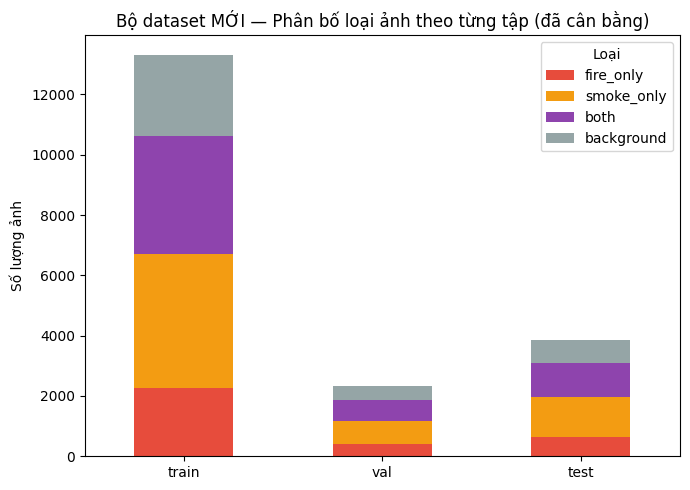

In [12]:
df_cat[['fire_only', 'smoke_only', 'both', 'background']].plot(
    kind='bar', stacked=True, figsize=(7, 5), color=['#e74c3c', '#f39c12', '#8e44ad', '#95a5a6'])
plt.title('Bộ dataset MỚI — Phân bố loại ảnh theo từng tập (đã cân bằng)')
plt.ylabel('Số lượng ảnh')
plt.xticks(rotation=0)
plt.legend(title='Loại')
plt.tight_layout()
plt.show()

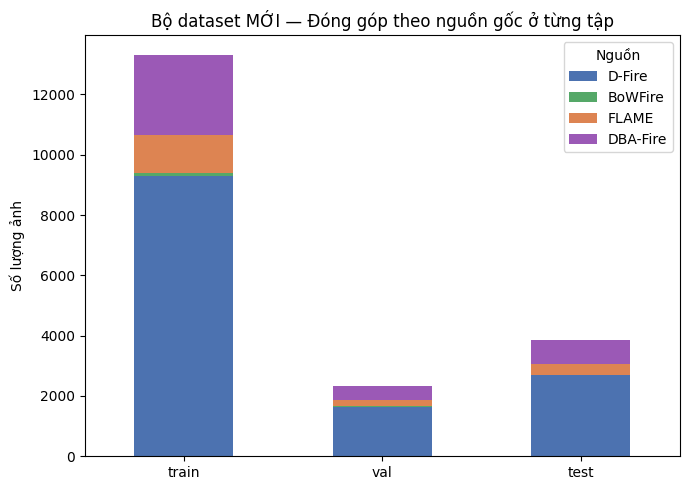

In [13]:
df_src[['D-Fire', 'BoWFire', 'FLAME', 'DBA-Fire']].plot(
    kind='bar', stacked=True, figsize=(7, 5), color=['#4C72B0', '#55A868', '#DD8452', '#9B59B6'])
plt.title('Bộ dataset MỚI — Đóng góp theo nguồn gốc ở từng tập')
plt.ylabel('Số lượng ảnh')
plt.xticks(rotation=0)
plt.legend(title='Nguồn')
plt.tight_layout()
plt.show()

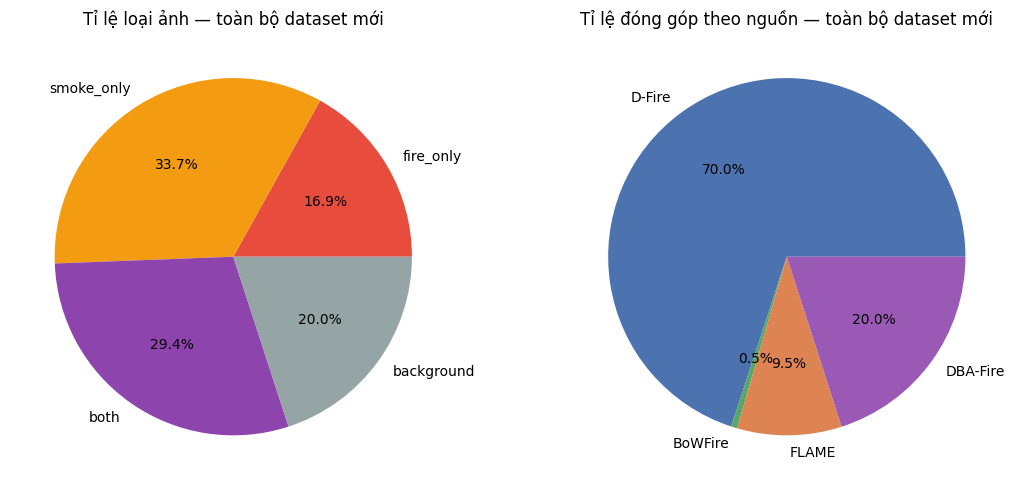

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

total_cat = df_cat[['fire_only', 'smoke_only', 'both', 'background']].sum()
axes[0].pie(total_cat, labels=total_cat.index, autopct='%1.1f%%',
            colors=['#e74c3c', '#f39c12', '#8e44ad', '#95a5a6'])
axes[0].set_title('Tỉ lệ loại ảnh — toàn bộ dataset mới')

total_src = df_src[['D-Fire', 'BoWFire', 'FLAME', 'DBA-Fire']].sum()
axes[1].pie(total_src, labels=total_src.index, autopct='%1.1f%%',
            colors=['#4C72B0', '#55A868', '#DD8452', '#9B59B6'])
axes[1].set_title('Tỉ lệ đóng góp theo nguồn — toàn bộ dataset mới')

plt.tight_layout()
plt.show()

Đã lưu 4 file CSV thống kê.


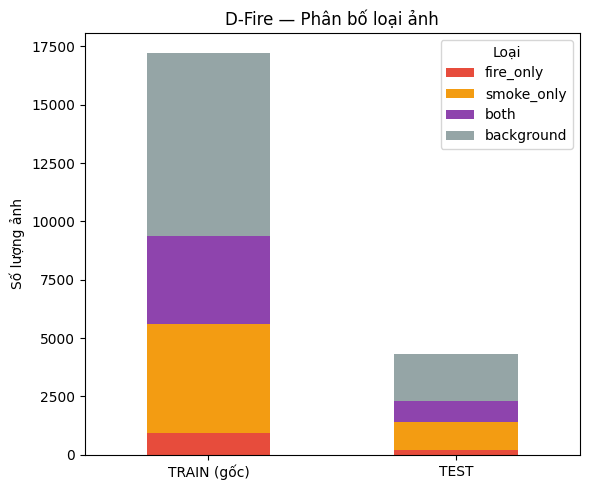

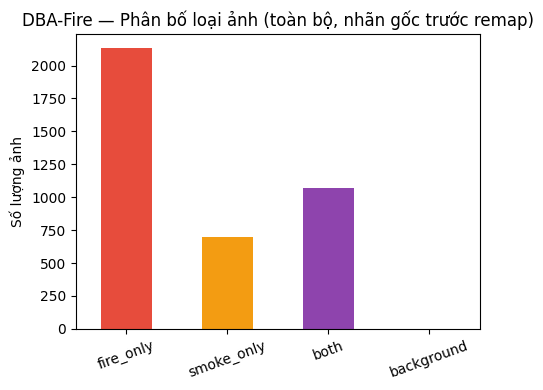

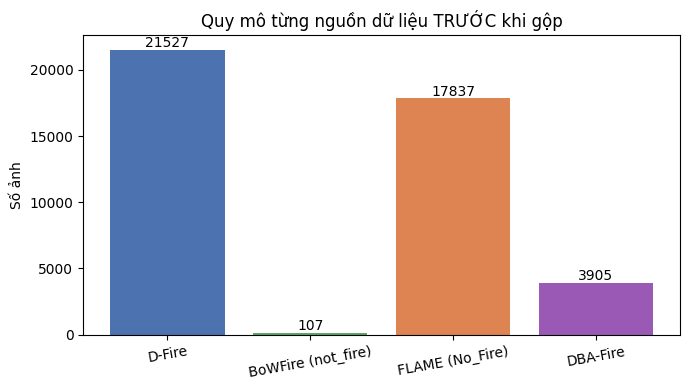

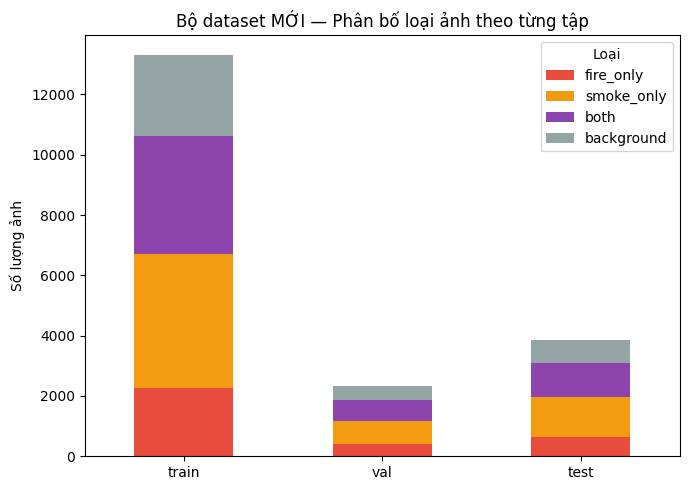

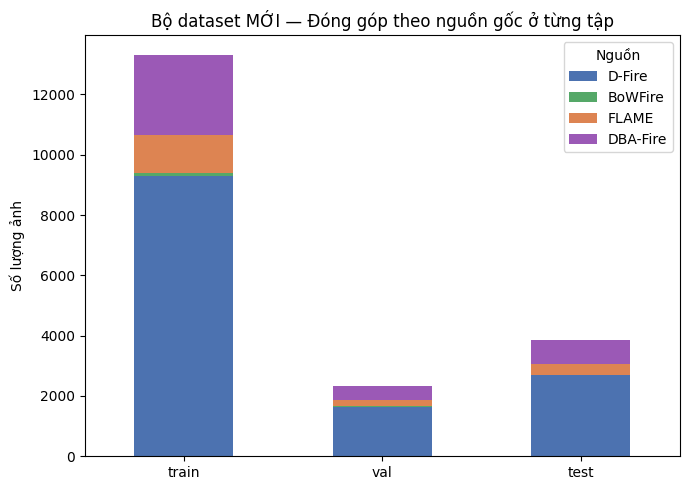

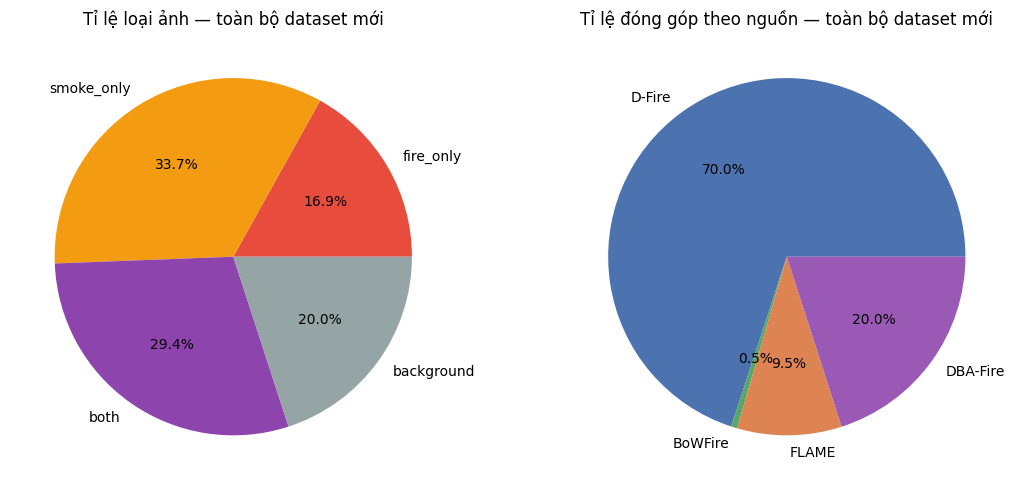


Đã lưu xong toàn bộ report assets tại: /kaggle/working/report_assets
Danh sách file: ['02_dba_fire_phan_bo.png', 'dong_gop_theo_nguon.csv', '04_phan_bo_sau_gop.png', '05_dong_gop_nguon_sau_gop.png', 'quy_mo_truoc_khi_gop.csv', 'dba_fire_goc_thong_ke.csv', 'dfire_goc_thong_ke.csv', '00_tom_tat_so_lieu.txt', '06_ti_le_tong_the.png', 'phan_bo_loai_anh_theo_tap.csv', '01_dfire_phan_bo.png', '03_quy_mo_truoc_gop.png']

File zip báo cáo: /kaggle/working/data_report_assets.zip


In [15]:
# Lưu toàn bộ output

REPORT_DIR = "/kaggle/working/report_assets"
os.makedirs(REPORT_DIR, exist_ok=True)

df_cat.to_csv(os.path.join(REPORT_DIR, "phan_bo_loai_anh_theo_tap.csv"))
df_src.to_csv(os.path.join(REPORT_DIR, "dong_gop_theo_nguon.csv"))

df_dfire_new.to_csv(os.path.join(REPORT_DIR, "dfire_goc_thong_ke.csv"))
df_dba.to_csv(os.path.join(REPORT_DIR, "dba_fire_goc_thong_ke.csv"))

pd.DataFrame([totals_before]).T.rename(columns={0: 'so_anh'}).to_csv(
    os.path.join(REPORT_DIR, "quy_mo_truoc_khi_gop.csv"))

print("Đã lưu 4 file CSV thống kê.")

# Biểu đồ D-Fire gốc
df_dfire_new.plot(kind='bar', stacked=True, figsize=(6, 5), color=['#e74c3c', '#f39c12', '#8e44ad', '#95a5a6'])
plt.title('D-Fire — Phân bố loại ảnh')
plt.ylabel('Số lượng ảnh'); plt.xticks(rotation=0); plt.legend(title='Loại')
plt.tight_layout()
plt.savefig(os.path.join(REPORT_DIR, "01_dfire_phan_bo.png"), dpi=150)
plt.show()

# Biểu đồ DBA-Fire gốc
df_dba.plot(kind='bar', figsize=(5, 4), color=['#e74c3c', '#f39c12', '#8e44ad', '#95a5a6'])
plt.title('DBA-Fire — Phân bố loại ảnh (toàn bộ, nhãn gốc trước remap)')
plt.ylabel('Số lượng ảnh'); plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(os.path.join(REPORT_DIR, "02_dba_fire_phan_bo.png"), dpi=150)
plt.show()

# Biểu đồ quy mô trước khi gộp
plt.figure(figsize=(7, 4))
bars = plt.bar(totals_before.keys(), totals_before.values(), color=['#4C72B0', '#55A868', '#DD8452', '#9B59B6'])
plt.title('Quy mô từng nguồn dữ liệu TRƯỚC khi gộp')
plt.ylabel('Số ảnh')
for b, v in zip(bars, totals_before.values()):
    plt.text(b.get_x() + b.get_width()/2, v + max(totals_before.values())*0.01, str(v), ha='center')
plt.xticks(rotation=10)
plt.tight_layout()
plt.savefig(os.path.join(REPORT_DIR, "03_quy_mo_truoc_gop.png"), dpi=150)
plt.show()

# Biểu đồ phân bố loại ảnh SAU khi gộp
df_cat[['fire_only', 'smoke_only', 'both', 'background']].plot(
    kind='bar', stacked=True, figsize=(7, 5), color=['#e74c3c', '#f39c12', '#8e44ad', '#95a5a6'])
plt.title('Bộ dataset MỚI — Phân bố loại ảnh theo từng tập')
plt.ylabel('Số lượng ảnh'); plt.xticks(rotation=0); plt.legend(title='Loại')
plt.tight_layout()
plt.savefig(os.path.join(REPORT_DIR, "04_phan_bo_sau_gop.png"), dpi=150)
plt.show()

# Biểu đồ đóng góp theo nguồn SAU khi gộp
df_src[['D-Fire', 'BoWFire', 'FLAME', 'DBA-Fire']].plot(
    kind='bar', stacked=True, figsize=(7, 5), color=['#4C72B0', '#55A868', '#DD8452', '#9B59B6'])
plt.title('Bộ dataset MỚI — Đóng góp theo nguồn gốc ở từng tập')
plt.ylabel('Số lượng ảnh'); plt.xticks(rotation=0); plt.legend(title='Nguồn')
plt.tight_layout()
plt.savefig(os.path.join(REPORT_DIR, "05_dong_gop_nguon_sau_gop.png"), dpi=150)
plt.show()

# 2 biểu đồ tròn tổng thể
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
total_cat = df_cat[['fire_only', 'smoke_only', 'both', 'background']].sum()
axes[0].pie(total_cat, labels=total_cat.index, autopct='%1.1f%%',
            colors=['#e74c3c', '#f39c12', '#8e44ad', '#95a5a6'])
axes[0].set_title('Tỉ lệ loại ảnh — toàn bộ dataset mới')

total_src = df_src[['D-Fire', 'BoWFire', 'FLAME', 'DBA-Fire']].sum()
axes[1].pie(total_src, labels=total_src.index, autopct='%1.1f%%',
            colors=['#4C72B0', '#55A868', '#DD8452', '#9B59B6'])
axes[1].set_title('Tỉ lệ đóng góp theo nguồn — toàn bộ dataset mới')
plt.tight_layout()
plt.savefig(os.path.join(REPORT_DIR, "06_ti_le_tong_the.png"), dpi=150)
plt.show()

summary_lines = [
    "TÓM TẮT SỐ LIỆU DATASET — FinalSFD_YOLO_Dataset",
    "=" * 50,
    "",
    "PHÂN BỐ LOẠI ẢNH THEO TỪNG TẬP:",
    df_cat.to_string(),
    "",
    "ĐÓNG GÓP THEO TỪNG NGUỒN GỐC:",
    df_src.to_string(),
    "",
    "TỈ LỆ MẤT CÂN BẰNG SMOKE:FIRE THEO TỪNG TẬP:",
]
for split in df_cat.index:
    fire = df_cat.loc[split, 'fire_only'] + df_cat.loc[split, 'both']
    smoke = df_cat.loc[split, 'smoke_only'] + df_cat.loc[split, 'both']
    summary_lines.append(f"  {split}: Fire={fire}, Smoke={smoke}, Tỉ lệ Smoke:Fire = {smoke/fire:.2f}:1")

with open(os.path.join(REPORT_DIR, "00_tom_tat_so_lieu.txt"), 'w', encoding='utf-8') as f:
    f.write("\n".join(summary_lines))

print("\nĐã lưu xong toàn bộ report assets tại:", REPORT_DIR)
print("Danh sách file:", os.listdir(REPORT_DIR))

report_zip = shutil.make_archive("/kaggle/working/data_report_assets", 'zip', REPORT_DIR)
print("\nFile zip báo cáo:", report_zip)

In [16]:
!zip -rq /kaggle/working/FinalSFD_YOLO_Dataset.zip /kaggle/working/FinalSFD_YOLO_Dataset

shutil.rmtree('/kaggle/working/FinalSFD_YOLO_Dataset')
print("Đã nén xong!!!")

Đã nén xong!!!
